In [50]:
import pandas as pd
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from PIL import Image
import math

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Library berhasil diimpor!")

Library berhasil diimpor!


In [33]:
!apt-get update -qq
!apt-get install -y tesseract-ocr
!pip install -q pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (5.3.4-1build5).
0 upgraded, 0 newly installed, 0 to remove and 24 not upgraded.


In [34]:
import pytesseract

print("Versi Tesseract:", pytesseract.get_tesseract_version())

Versi Tesseract: 5.3.4


In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
folder = "/content/drive/MyDrive/PCD7"

print(os.listdir(folder))

['Absent', 'Present']


In [5]:
for subfolder in ["Absent", "Present"]:
    path = os.path.join(folder, subfolder)
    files = os.listdir(path)

    print(f"\nFolder {subfolder}: {len(files)} file")

    for nama in files[:10]:
        print(" -", nama)



Folder Absent: 9 file
 - gambar 1 pcd.jpg
 - gambar 2 pcd.jpg
 - gambar 3 pcd.jpg
 - gambar 4 pcd.jpg
 - gambar 5 pcd.jpg
 - gambar 6 pcd.jpg
 - gambar 7 pcd.jpg
 - gambar 8 pcd.jpg
 - gambar 9 pcd.jpg

Folder Present: 9 file
 - 01_HighQuality_Enhanced.jpg
 - 02_LowContrast.jpg
 - 03_Blurred.jpg
 - 04_HighNoise.jpg
 - 05_LowResolution_Upsampled.jpg
 - 06_Faded_Underexposed.jpg
 - 08_JPEGCompression_Artifacts.jpg
 - 07_ColorShift_WarmTint.jpg
 - 09_CombinedDegradation.jpg


Kategori Absent: 9 gambar


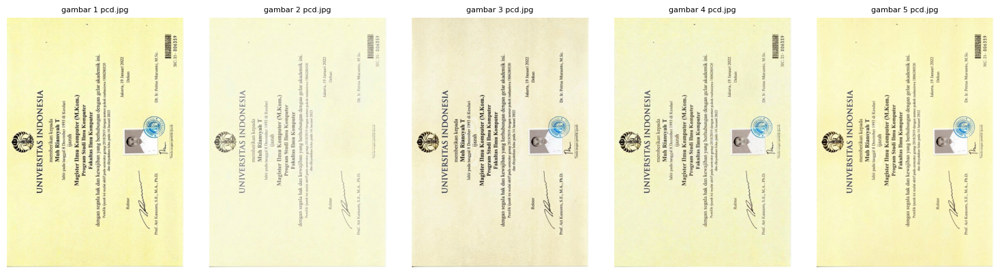

Kategori Present: 9 gambar


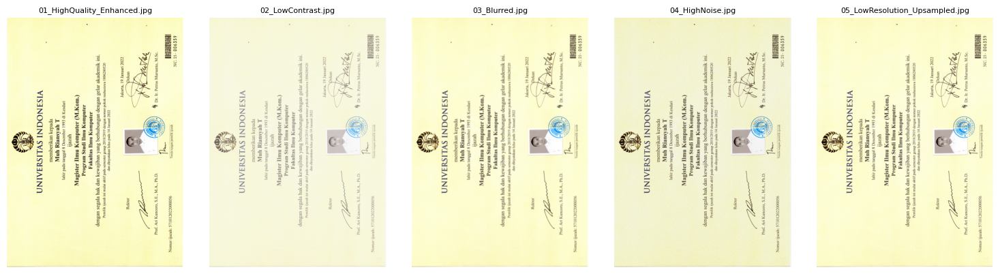

In [6]:
for kategori in ["Absent", "Present"]:
    path = os.path.join(folder, kategori)

    files = [
        f for f in os.listdir(path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    print(f"Kategori {kategori}: {len(files)} gambar")

    if len(files) == 0:
        print("Tidak ada gambar yang ditemukan.")
        continue

    files = sorted(files)[:5]
    fig, axes = plt.subplots(1, len(files), figsize=(15, 4))

    if len(files) == 1:
        axes = [axes]

    for ax, nama in zip(axes, files):
        img = Image.open(os.path.join(path, nama))
        ax.imshow(img)
        ax.set_title(nama, fontsize=8)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


Greyscale


In [7]:

import cv2

output_grayscale = "/content/drive/MyDrive/PCD7_Grayscale"

jumlah_berhasil = 0
jumlah_gagal = 0

for kategori in ["Absent", "Present"]:
    path_input = os.path.join(folder, kategori)
    path_output = os.path.join(output_grayscale, kategori)

    os.makedirs(path_output, exist_ok=True)

    files = sorted([
        f for f in os.listdir(path_input)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ])

    for nama in files:
        lokasi_input = os.path.join(path_input, nama)
        gambar = cv2.imread(lokasi_input)

        if gambar is None:
            print(f"Gagal membaca: {lokasi_input}")
            jumlah_gagal += 1
            continue

        grayscale = cv2.cvtColor(gambar, cv2.COLOR_BGR2GRAY)

        lokasi_output = os.path.join(path_output, nama)
        berhasil = cv2.imwrite(lokasi_output, grayscale)

        if berhasil:
            jumlah_berhasil += 1
        else:
            print(f"Gagal menyimpan: {lokasi_output}")
            jumlah_gagal += 1

print("Proses grayscale selesai.")
print("Berhasil:", jumlah_berhasil, "gambar")
print("Gagal:", jumlah_gagal, "gambar")
print("Lokasi hasil:", output_grayscale)


Proses grayscale selesai.
Berhasil: 18 gambar
Gagal: 0 gambar
Lokasi hasil: /content/drive/MyDrive/PCD7_Grayscale


In [8]:

for kategori in ["Absent", "Present"]:
    path = os.path.join(output_grayscale, kategori)

    files = [
        f for f in os.listdir(path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    print(f"{kategori}: {len(files)} gambar grayscale")


Absent: 18 gambar grayscale
Present: 9 gambar grayscale


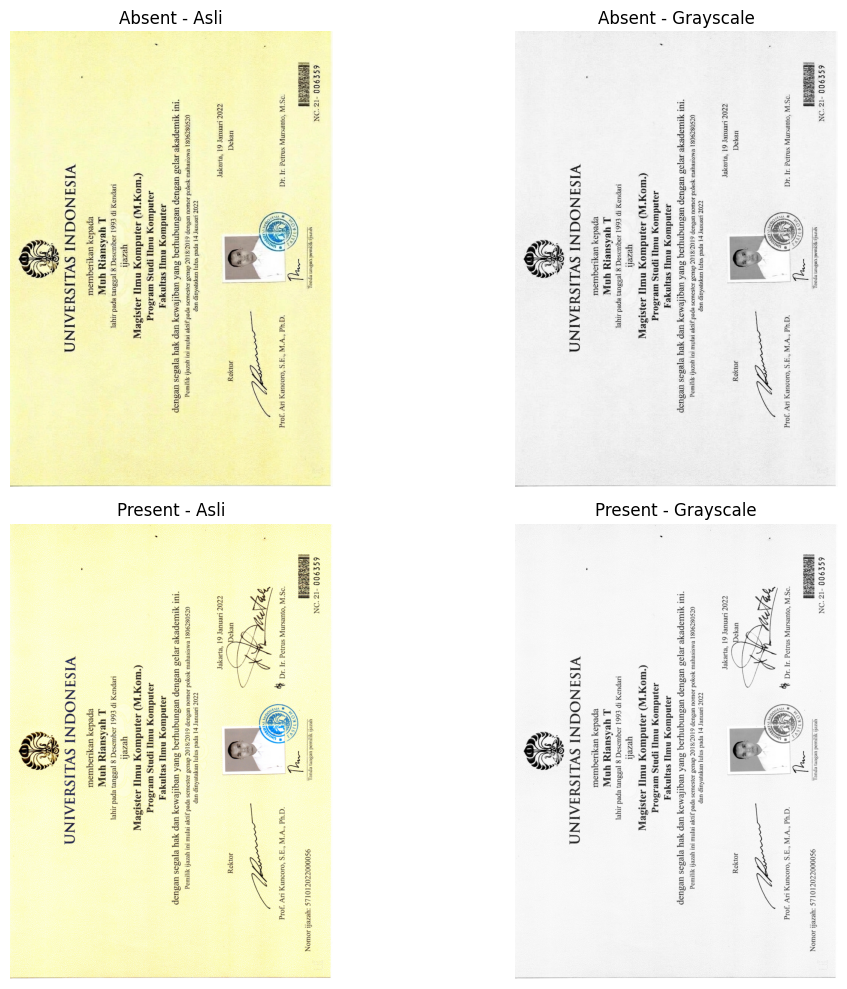

In [9]:


# Folder dataset asli dan hasil grayscale
folder_asli = "/content/drive/MyDrive/PCD7"
folder_gray = "/content/drive/MyDrive/PCD7_Grayscale"

kategori = ["Absent", "Present"]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, kelas in enumerate(kategori):
    folder = os.path.join(folder_asli, kelas)
    folder_hasil = os.path.join(folder_gray, kelas)

    daftar_file = sorted([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    if not daftar_file:
        print(f"Tidak ada gambar di folder {folder}")
        continue

    nama_file = daftar_file[0]

    gambar_asli = cv2.imread(
        os.path.join(folder, nama_file)
    )
    gambar_gray = cv2.imread(
        os.path.join(folder_hasil, nama_file),
        cv2.IMREAD_GRAYSCALE
    )

    if gambar_asli is None or gambar_gray is None:
        print(f"Gagal membaca gambar: {nama_file}")
        continue

    gambar_asli = cv2.cvtColor(
        gambar_asli, cv2.COLOR_BGR2RGB
    )

    axes[i, 0].imshow(gambar_asli)
    axes[i, 0].set_title(f"{kelas} - Asli")

    axes[i, 1].imshow(gambar_gray, cmap="gray")
    axes[i, 1].set_title(f"{kelas} - Grayscale")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

#Coordinat Gambar Absent

Nama gambar : 01_HighQuality_Enhanced.jpg
Lebar       : 2481 piksel
Tinggi      : 3506 piksel


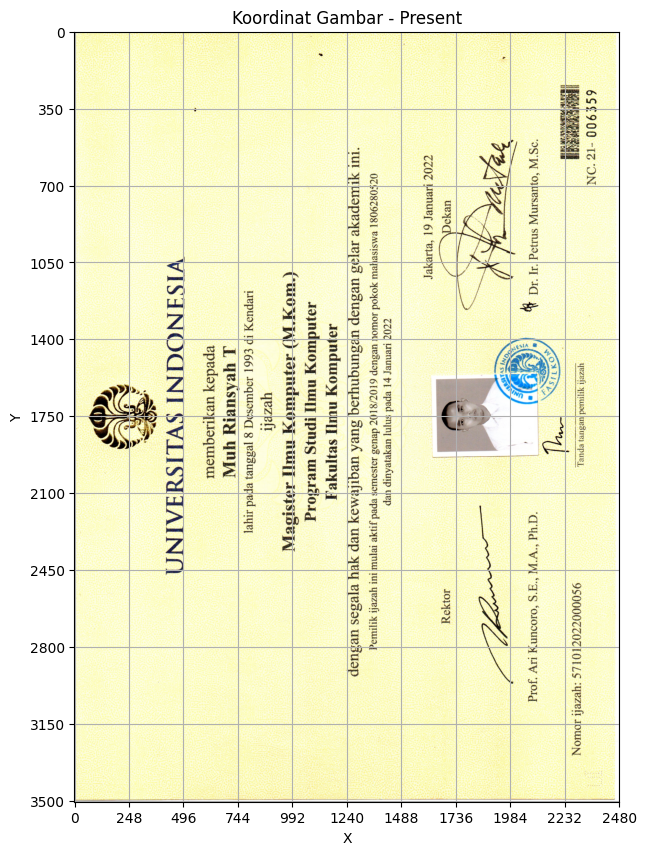

In [10]:
# Pilih kategori gambar
kategori = "Present"  # Ganti menjadi "Absent" jika diperlukan

# Lokasi folder dataset Tugas 7
folder = f"/content/drive/MyDrive/PCD7/{kategori}"

# Ambil daftar gambar
files = sorted([
    f for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

# Pilih gambar pertama
nama_file = files[0]
path = os.path.join(folder, nama_file)

# Baca gambar
img = cv2.imread(path)

if img is None:
    raise ValueError(f"Gambar gagal dibaca: {path}")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Ambil ukuran gambar sebenarnya
tinggi, lebar = img.shape[:2]

print(f"Nama gambar : {nama_file}")
print(f"Lebar       : {lebar} piksel")
print(f"Tinggi      : {tinggi} piksel")

# Tampilkan gambar beserta koordinat
plt.figure(figsize=(12, 10))
plt.imshow(img_rgb)

plt.xticks(range(0, lebar + 1, max(1, lebar // 10)))
plt.yticks(range(0, tinggi + 1, max(1, tinggi // 10)))
plt.grid()

plt.xlabel("X")
plt.ylabel("Y")
plt.title(f"Koordinat Gambar - {kategori}")

plt.show()

##Crop bagian Tanda Tangan

Total gambar ditemukan: 9
Total gambar berhasil di-crop: 9


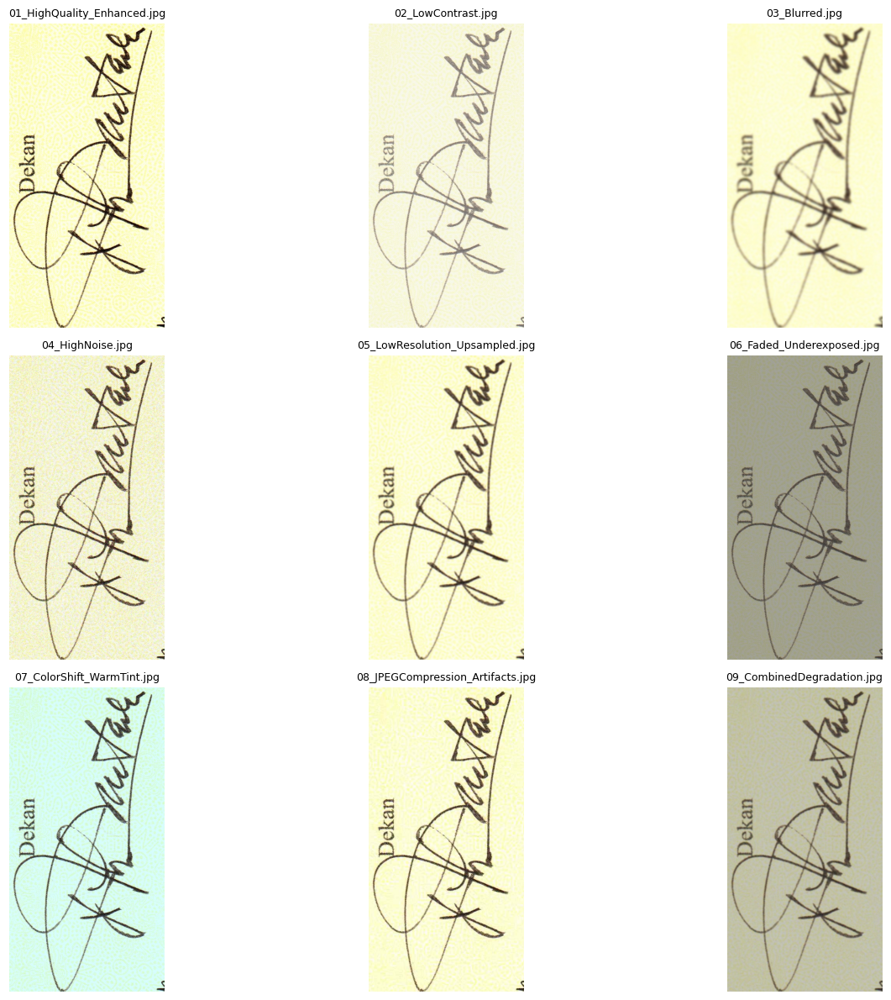

In [19]:
# Lokasi folder gambar Present
folder = "/content/drive/MyDrive/PCD7/Present"

files = sorted([
    f for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

if not files:
    raise FileNotFoundError("Tidak ada gambar di folder Present!")

# Koordinat crop tanda tangan Dekan
x1, y1 = 1650, 480
x2, y2 = 2050, 1265

hasil_crop_present = {}

# Proses semua gambar
for nama_file in files:
    path = os.path.join(folder, nama_file)
    img = cv2.imread(path)

    if img is None:
        print(f"Gambar gagal dibaca: {nama_file}")
        continue

    tinggi, lebar = img.shape[:2]

    if x2 > lebar or y2 > tinggi:
        print(f"Koordinat crop melebihi ukuran gambar: {nama_file}")
        continue

    ttd_present = img[y1:y2, x1:x2]
    hasil_crop_present[nama_file] = ttd_present

print("Total gambar ditemukan:", len(files))
print("Total gambar berhasil di-crop:", len(hasil_crop_present))

# Tampilkan hasil dalam 3 kolom
jumlah = len(hasil_crop_present)
kolom = 3
baris = math.ceil(jumlah / kolom)

fig, axes = plt.subplots(
    baris, kolom,
    figsize=(15, 4 * baris)
)

# Pastikan axes selalu bisa diakses sebagai array
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for ax, (nama_file, hasil) in zip(
    axes, hasil_crop_present.items()
):
    hasil_rgb = cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB)
    ax.imshow(hasil_rgb)
    ax.set_title(nama_file, fontsize=9)
    ax.axis("off")

# Sembunyikan kotak kosong jika jumlah gambar bukan kelipatan 3
for ax in axes[jumlah:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

##Crop bagian Nomor Ijazah

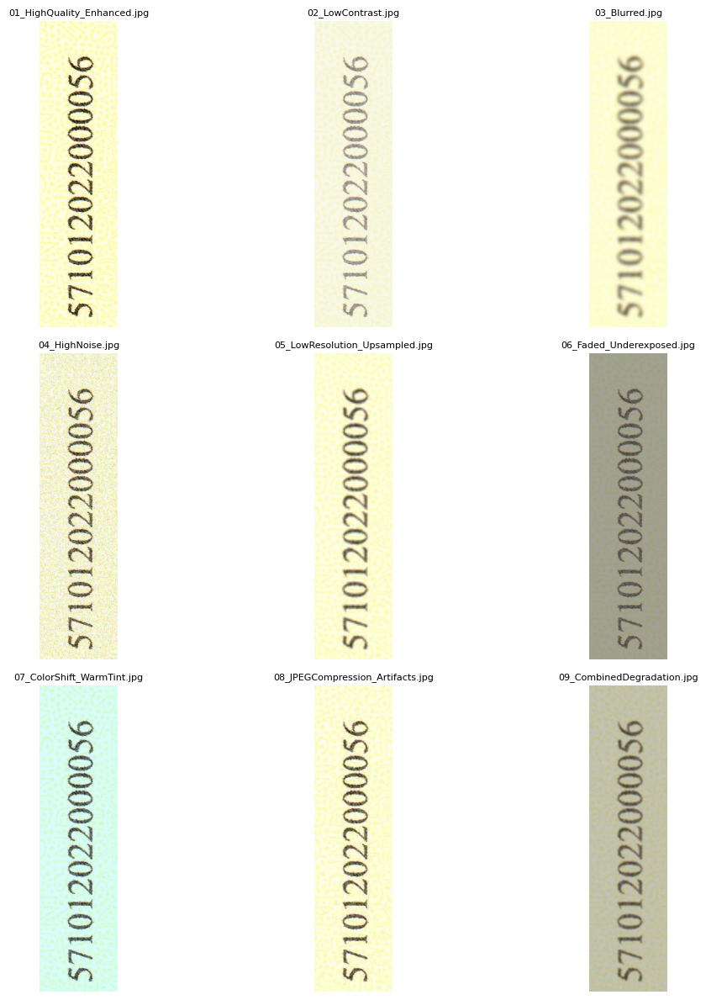

Total gambar ditemukan: 9
Total nomor ijazah berhasil di-crop: 9


In [24]:
# Lokasi folder gambar Present
folder = "/content/drive/MyDrive/PCD7/Present"

files = sorted([
    f for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

if not files:
    raise FileNotFoundError("Tidak ada gambar di folder Present!")

# Koordinat crop nomor ijazah
x1, y1 = 2220, 2450
x2, y2 = 2350, 2960

hasil_crop_nomor = {}

# Crop semua gambar
for nama_file in files:
    path = os.path.join(folder, nama_file)
    img = cv2.imread(path)

    if img is None:
        print(f"Gambar gagal dibaca: {nama_file}")
        continue

    tinggi, lebar = img.shape[:2]

    if x2 > lebar or y2 > tinggi:
        print(f"Koordinat crop melebihi ukuran gambar: {nama_file}")
        continue

    # Crop area nomor ijazah
    nomor_crop = img[y1:y2, x1:x2]
    hasil_crop_nomor[nama_file] = nomor_crop

# Tampilkan dalam 3 kolom
jumlah = len(hasil_crop_nomor)
kolom = 3
baris = math.ceil(jumlah / kolom)

fig, axes = plt.subplots(
    baris, kolom,
    figsize=(12, 4 * baris)
)

axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for ax, (nama_file, hasil) in zip(
    axes, hasil_crop_nomor.items()
):
    hasil_rgb = cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB)
    ax.imshow(hasil_rgb)
    ax.set_title(nama_file, fontsize=8)
    ax.axis("off")

for ax in axes[jumlah:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Total gambar ditemukan:", len(files))
print("Total nomor ijazah berhasil di-crop:", jumlah)

##Greyscale untuk gamabr present

Total gambar ditemukan: 9
Total gambar berhasil diproses: 9


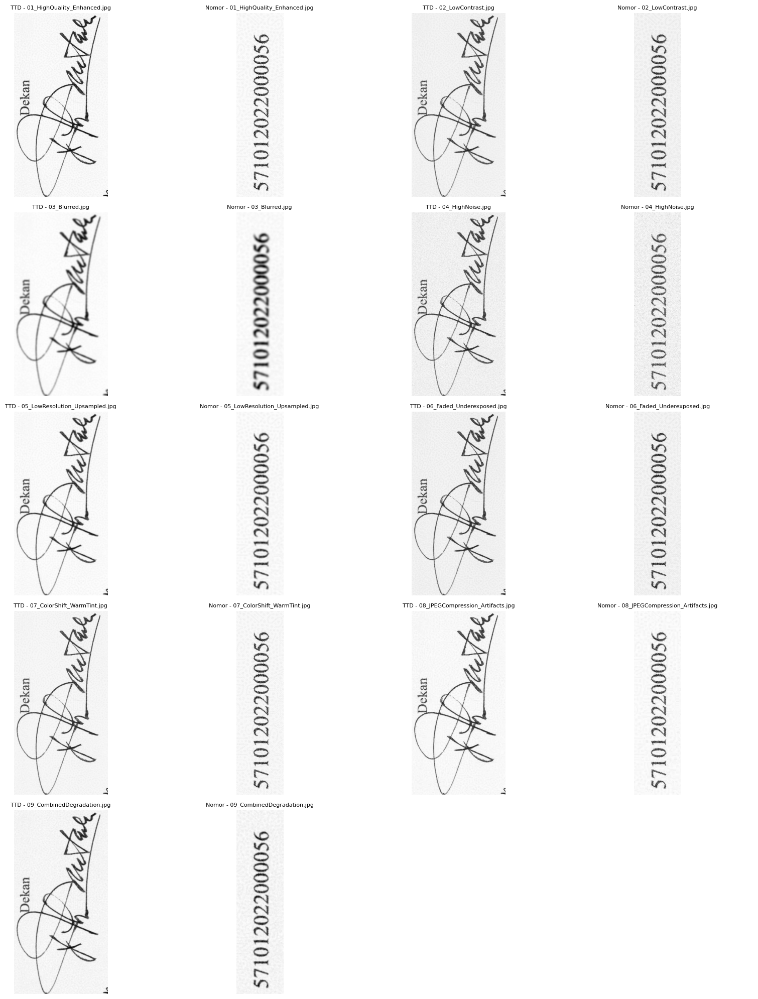

In [28]:
# Lokasi folder gambar Present
folder = "/content/drive/MyDrive/PCD7/Present"

files = sorted([
    f for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

if not files:
    raise FileNotFoundError("Tidak ada gambar di folder Present!")

# Koordinat crop tanda tangan Dekan
x1_ttd, y1_ttd = 1650, 480
x2_ttd, y2_ttd = 2050, 1265

# Koordinat crop nomor ijazah
x1_nomor, y1_nomor = 2220, 2450
x2_nomor, y2_nomor = 2350, 2960

# Menyimpan hasil grayscale dan crop
hasil_present = {}

for nama_file in files:
    path = os.path.join(folder, nama_file)
    img = cv2.imread(path)

    if img is None:
        print(f"Gambar gagal dibaca: {nama_file}")
        continue

    tinggi, lebar = img.shape[:2]

    # Periksa apakah kedua area crop sesuai ukuran gambar
    if (x2_ttd > lebar or y2_ttd > tinggi or
        x2_nomor > lebar or y2_nomor > tinggi):
        print(f"Ukuran gambar tidak sesuai: {nama_file}")
        print(f"Ukuran: {lebar} x {tinggi}")
        continue

    # Konversi seluruh gambar menjadi grayscale
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Crop tanda tangan Dekan dari gambar grayscale
    ttd_gray = img_gray[y1_ttd:y2_ttd, x1_ttd:x2_ttd]

    # Crop nomor ijazah dari gambar grayscale
    nomor_gray = img_gray[
        y1_nomor:y2_nomor,
        x1_nomor:x2_nomor
    ]

    hasil_present[nama_file] = {
        "grayscale": img_gray,
        "ttd": ttd_gray,
        "nomor": nomor_gray
    }

print("Total gambar ditemukan:", len(files))
print("Total gambar berhasil diproses:", len(hasil_present))

# Tampilkan hasil crop dalam 4 kolom sejajar
jumlah = len(hasil_present)

if jumlah > 0:
    kolom = 4
    baris = math.ceil(jumlah / 2)

    fig, axes = plt.subplots(
        baris, kolom,
        figsize=(16, 4 * baris)
    )

    axes = axes.flatten()

    for i, (nama_file, hasil) in enumerate(hasil_present.items()):
        # Kolom 1 dan 2: tanda tangan Dekan
        ax_ttd = axes[i * 2]
        ax_ttd.imshow(hasil["ttd"], cmap="gray")
        ax_ttd.set_title(f"TTD - {nama_file}", fontsize=8)
        ax_ttd.axis("off")

        # Kolom 3 dan 4: nomor ijazah
        ax_nomor = axes[i * 2 + 1]
        ax_nomor.imshow(hasil["nomor"], cmap="gray")
        ax_nomor.set_title(f"Nomor - {nama_file}", fontsize=8)
        ax_nomor.axis("off")

    # Sembunyikan subplot kosong
    for ax in axes[len(hasil_present) * 2:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

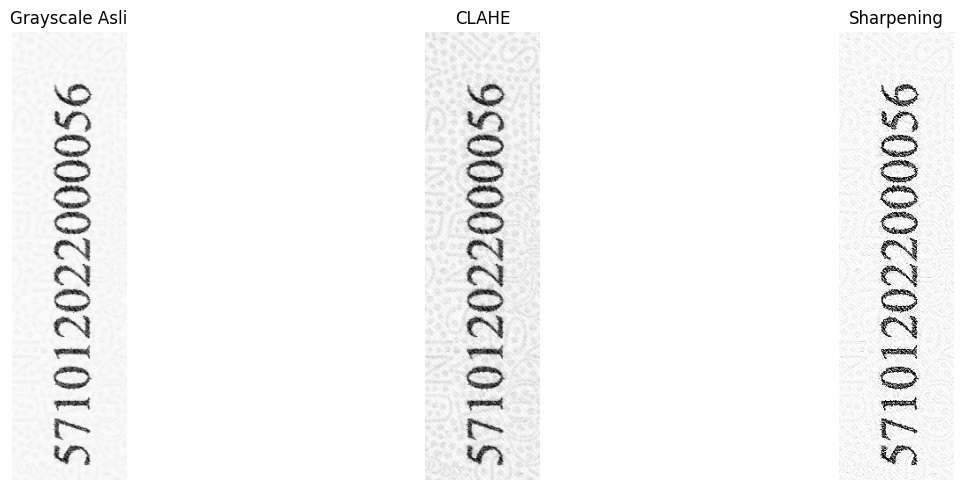

Nama gambar: 01_HighQuality_Enhanced.jpg
Ukuran crop: (510, 130)


In [30]:
# Ambil satu gambar dari hasil cropping nomor ijazah
nama_file = next(iter(hasil_present))
nomor_gray = hasil_present[nama_file]["nomor"]

# Metode 1: CLAHE untuk meningkatkan kontras
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(4, 4)
)
hasil_clahe = clahe.apply(nomor_gray)

# Metode 2: Sharpening untuk mempertajam karakter
kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

hasil_sharpen = cv2.filter2D(
    nomor_gray,
    -1,
    kernel
)

# Tampilkan hasil perbandingan
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(nomor_gray, cmap="gray")
axes[0].set_title("Grayscale Asli")

axes[1].imshow(hasil_clahe, cmap="gray")
axes[1].set_title("CLAHE")

axes[2].imshow(hasil_sharpen, cmap="gray")
axes[2].set_title("Sharpening")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Nama gambar:", nama_file)
print("Ukuran crop:", nomor_gray.shape)

##Enhacment untuk nomor ijazah

#Coordinat Gambar Absent

Nama gambar : gambar 1 pcd.jpg
Lebar       : 864 piksel
Tinggi      : 1221 piksel


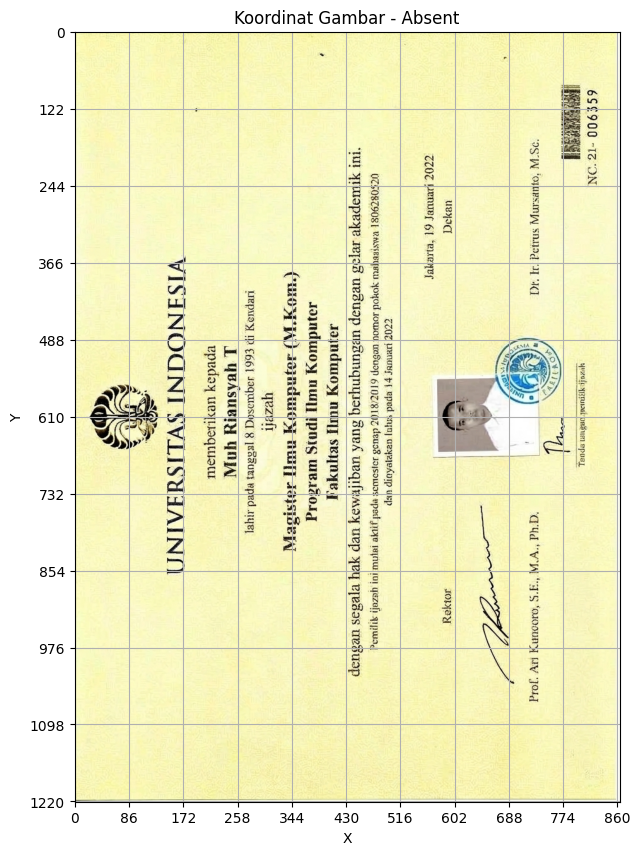

In [11]:
# Pilih kategori gambar
kategori = "Absent"

# Lokasi folder dataset Tugas 7
folder = f"/content/drive/MyDrive/PCD7/{kategori}"

# Ambil daftar gambar
files = sorted([
    f for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

# Pilih gambar pertama
nama_file = files[0]
path = os.path.join(folder, nama_file)

# Baca gambar
img = cv2.imread(path)

if img is None:
    raise ValueError(f"Gambar gagal dibaca: {path}")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Ambil ukuran gambar sebenarnya
tinggi, lebar = img.shape[:2]

print(f"Nama gambar : {nama_file}")
print(f"Lebar       : {lebar} piksel")
print(f"Tinggi      : {tinggi} piksel")

# Tampilkan gambar beserta koordinat
plt.figure(figsize=(12, 10))
plt.imshow(img_rgb)

plt.xticks(range(0, lebar + 1, max(1, lebar // 10)))
plt.yticks(range(0, tinggi + 1, max(1, tinggi // 10)))
plt.grid()

plt.xlabel("X")
plt.ylabel("Y")
plt.title(f"Koordinat Gambar - {kategori}")

plt.show()

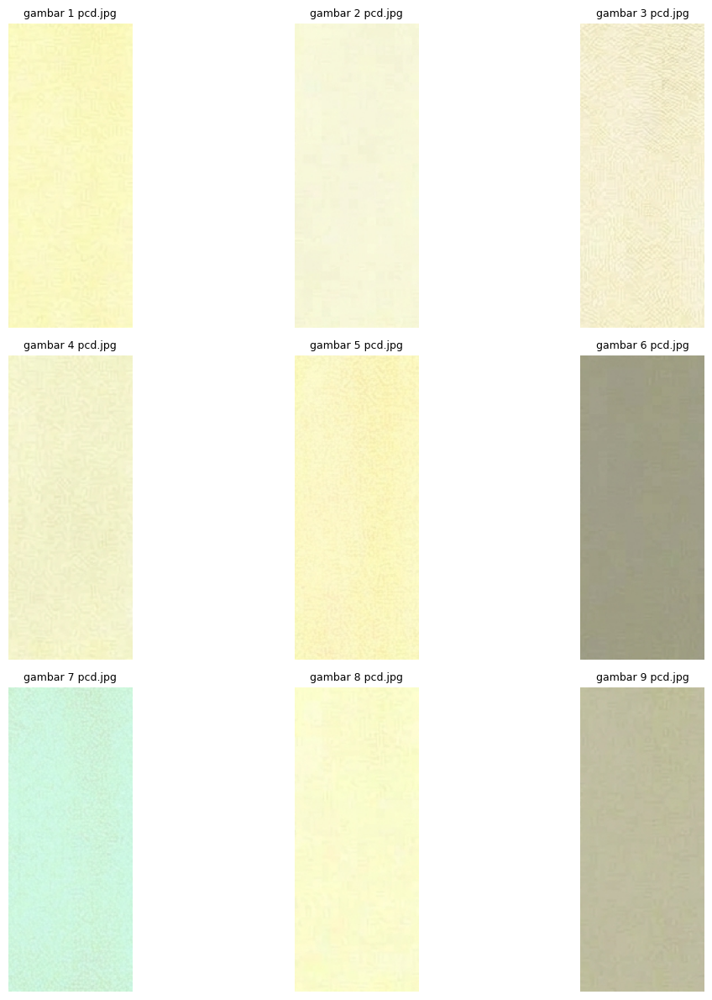

Total gambar ditemukan: 9
Total gambar berhasil di-crop: 9


In [26]:
# Lokasi folder gambar Absent
folder_absent = "/content/drive/MyDrive/PCD7/Absent"

files_absent = sorted([
    f for f in os.listdir(folder_absent)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

if not files_absent:
    raise FileNotFoundError("Tidak ada gambar di folder Absent!")

# Koordinat crop tanda tangan Dekan untuk gambar Absent
x1, y1 = 600, 180
x2, y2 = 710, 450

hasil_crop_absent = {}

# Crop semua gambar
for nama_file in files_absent:
    path = os.path.join(folder_absent, nama_file)
    img = cv2.imread(path)

    if img is None:
        print(f"Gambar gagal dibaca: {nama_file}")
        continue

    tinggi, lebar = img.shape[:2]

    if x2 > lebar or y2 > tinggi:
        print(f"Koordinat crop melebihi ukuran gambar: {nama_file}")
        continue

    ttd_absent = img[y1:y2, x1:x2]
    hasil_crop_absent[nama_file] = ttd_absent

# Tampilkan hasil dalam 3 kolom
jumlah = len(hasil_crop_absent)

if jumlah > 0:
    kolom = 3
    baris = math.ceil(jumlah / kolom)

    fig, axes = plt.subplots(
        baris, kolom,
        figsize=(12, 4 * baris)
    )

    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

    for ax, (nama_file, hasil) in zip(
        axes, hasil_crop_absent.items()
    ):
        hasil_rgb = cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB)
        ax.imshow(hasil_rgb)
        ax.set_title(nama_file, fontsize=9)
        ax.axis("off")

    for ax in axes[jumlah:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada gambar yang berhasil di-crop.")

print("Total gambar ditemukan:", len(files_absent))
print("Total gambar berhasil di-crop:", jumlah)

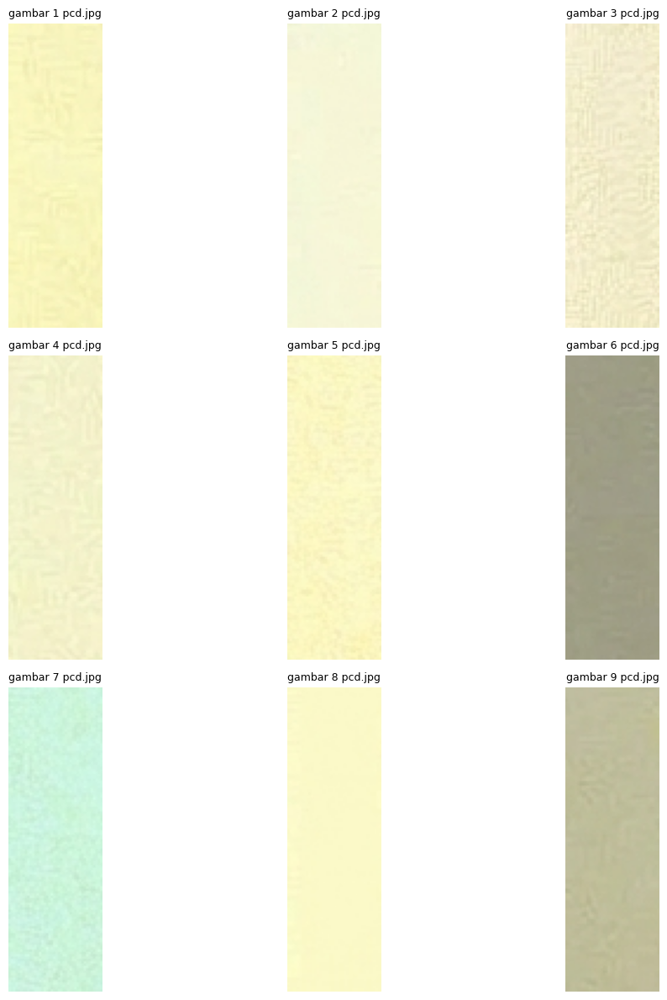

Total gambar ditemukan: 9
Total nomor ijazah berhasil di-crop: 9


In [27]:
# Lokasi folder gambar Absent
folder_absent = "/content/drive/MyDrive/PCD7/Absent"

files_absent = sorted([
    f for f in os.listdir(folder_absent)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

if not files_absent:
    raise FileNotFoundError("Tidak ada gambar di folder Absent!")

# Koordinat crop nomor ijazah untuk gambar Absent
x1, y1 = 770, 900
x2, y2 = 810, 1030

hasil_crop_nomor_absent = {}

# Crop semua gambar
for nama_file in files_absent:
    path = os.path.join(folder_absent, nama_file)
    img = cv2.imread(path)

    if img is None:
        print(f"Gambar gagal dibaca: {nama_file}")
        continue

    tinggi, lebar = img.shape[:2]

    if x2 > lebar or y2 > tinggi:
        print(f"Koordinat crop melebihi ukuran gambar: {nama_file}")
        continue

    nomor_crop = img[y1:y2, x1:x2]
    hasil_crop_nomor_absent[nama_file] = nomor_crop

# Tampilkan hasil dalam 3 kolom
jumlah = len(hasil_crop_nomor_absent)

if jumlah > 0:
    kolom = 3
    baris = math.ceil(jumlah / kolom)

    fig, axes = plt.subplots(
        baris, kolom,
        figsize=(12, 4 * baris)
    )

    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

    for ax, (nama_file, hasil) in zip(
        axes, hasil_crop_nomor_absent.items()
    ):
        hasil_rgb = cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB)
        ax.imshow(hasil_rgb)
        ax.set_title(nama_file, fontsize=9)
        ax.axis("off")

    for ax in axes[jumlah:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada gambar yang berhasil di-crop.")

print("Total gambar ditemukan:", len(files_absent))
print("Total nomor ijazah berhasil di-crop:", jumlah)

##Greyscale untuk gambar absent

Total gambar ditemukan: 9
Total gambar berhasil diproses: 9


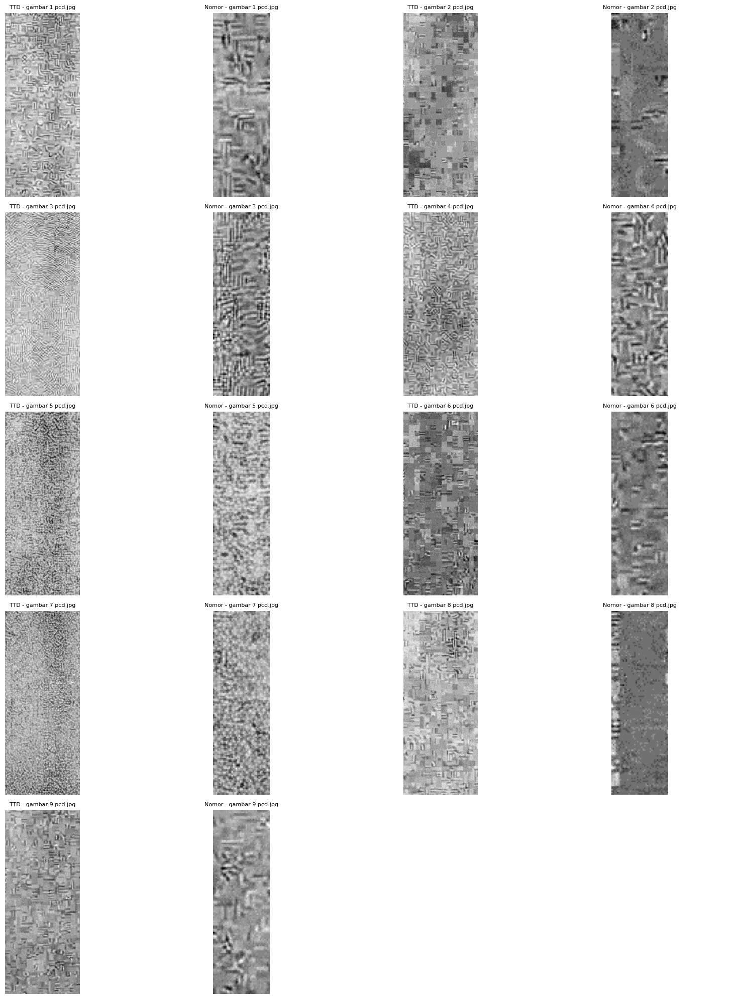

In [29]:
# Lokasi folder gambar Absent
folder_absent = "/content/drive/MyDrive/PCD7/Absent"

files_absent = sorted([
    f for f in os.listdir(folder_absent)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

if not files_absent:
    raise FileNotFoundError("Tidak ada gambar di folder Absent!")

# Koordinat crop tanda tangan Dekan - Absent
x1_ttd, y1_ttd = 600, 180
x2_ttd, y2_ttd = 710, 450

# Koordinat crop nomor ijazah - Absent
x1_nomor, y1_nomor = 770, 900
x2_nomor, y2_nomor = 810, 1030

# Simpan hasil grayscale dan crop
hasil_absent = {}

for nama_file in files_absent:
    path = os.path.join(folder_absent, nama_file)
    img = cv2.imread(path)

    if img is None:
        print(f"Gambar gagal dibaca: {nama_file}")
        continue

    tinggi, lebar = img.shape[:2]

    # Periksa apakah koordinat crop sesuai ukuran gambar
    if (x2_ttd > lebar or y2_ttd > tinggi or
        x2_nomor > lebar or y2_nomor > tinggi):
        print(f"Ukuran gambar tidak sesuai: {nama_file}")
        print(f"Ukuran: {lebar} x {tinggi}")
        continue

    # Konversi gambar menjadi grayscale
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Crop tanda tangan Dekan
    ttd_gray = img_gray[y1_ttd:y2_ttd, x1_ttd:x2_ttd]

    # Crop nomor ijazah
    nomor_gray = img_gray[
        y1_nomor:y2_nomor,
        x1_nomor:x2_nomor
    ]

    hasil_absent[nama_file] = {
        "grayscale": img_gray,
        "ttd": ttd_gray,
        "nomor": nomor_gray
    }

print("Total gambar ditemukan:", len(files_absent))
print("Total gambar berhasil diproses:", len(hasil_absent))

# Tampilkan hasil crop
jumlah = len(hasil_absent)

if jumlah > 0:
    kolom = 4
    baris = math.ceil(jumlah / 2)

    fig, axes = plt.subplots(
        baris, kolom,
        figsize=(16, 4 * baris)
    )

    axes = axes.flatten()

    for i, (nama_file, hasil) in enumerate(hasil_absent.items()):
        # Kolom 1: tanda tangan Dekan
        axes[i * 2].imshow(hasil["ttd"], cmap="gray")
        axes[i * 2].set_title(f"TTD - {nama_file}", fontsize=8)
        axes[i * 2].axis("off")

        # Kolom 2: nomor ijazah
        axes[i * 2 + 1].imshow(hasil["nomor"], cmap="gray")
        axes[i * 2 + 1].set_title(f"Nomor - {nama_file}", fontsize=8)
        axes[i * 2 + 1].axis("off")

    # Sembunyikan subplot yang kosong
    for ax in axes[jumlah * 2:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

#Enhancement nomr ijazah untuk gambar present dan absent

In [31]:

import os
import cv2
import numpy as np

# Folder penyimpanan hasil enhancement
folder_output = "/content/drive/MyDrive/PCD7_Enhancement"

metode = ["CLAHE", "Sharpening"]

for kategori, data_gambar in [
    ("Present", hasil_present),
    ("Absent", hasil_absent)
]:
    for nama_file, data in data_gambar.items():
        nomor_gray = data["nomor"]

        # Enhancement CLAHE
        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(4, 4)
        )
        hasil_clahe = clahe.apply(nomor_gray)

        # Enhancement Sharpening
        kernel = np.array([
            [0, -1, 0],
            [-1, 5, -1],
            [0, -1, 0]
        ])
        hasil_sharpen = cv2.filter2D(
            nomor_gray, -1, kernel
        )

        # Simpan hasil ke folder masing-masing
        nama_dasar = os.path.splitext(nama_file)[0]

        for nama_metode, hasil in [
            ("CLAHE", hasil_clahe),
            ("Sharpening", hasil_sharpen)
        ]:
            folder = os.path.join(
                folder_output, kategori, nama_metode
            )
            os.makedirs(folder, exist_ok=True)

            path_simpan = os.path.join(
                folder, nama_dasar + ".png"
            )
            cv2.imwrite(path_simpan, hasil)

print("Proses enhancement selesai!")
print("Lokasi penyimpanan:", folder_output)

Proses enhancement selesai!
Lokasi penyimpanan: /content/drive/MyDrive/PCD7_Enhancement


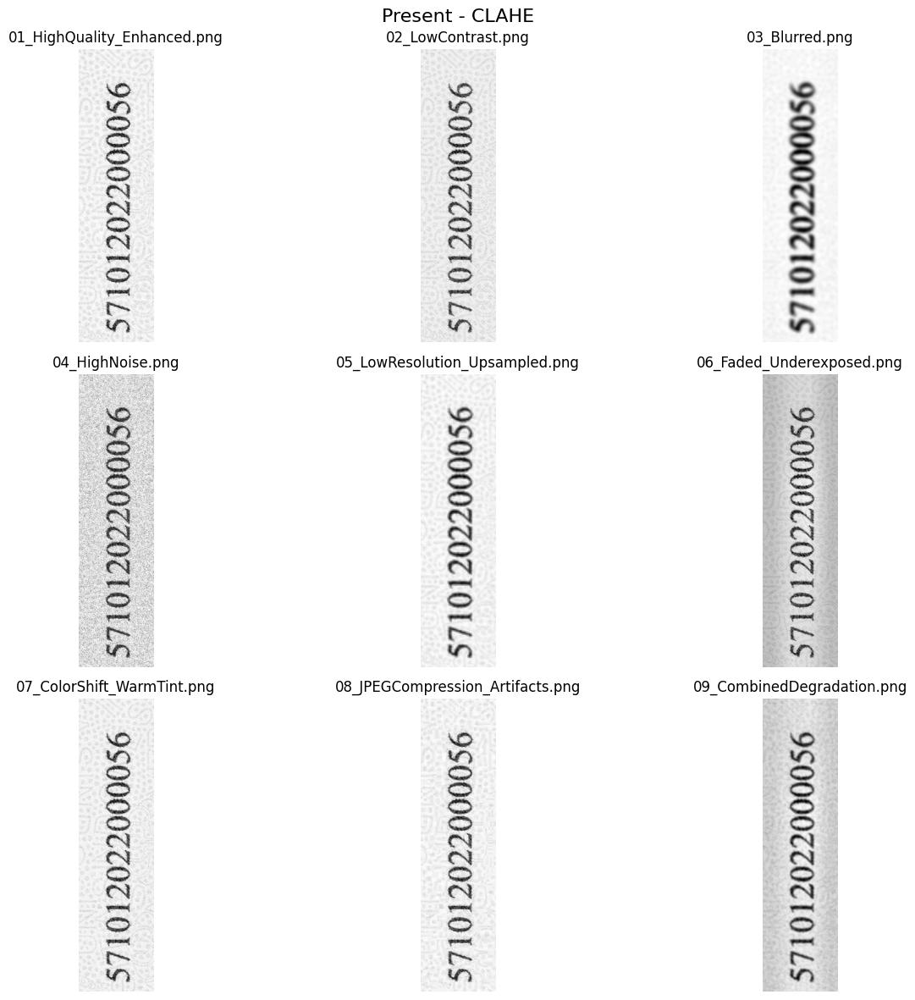

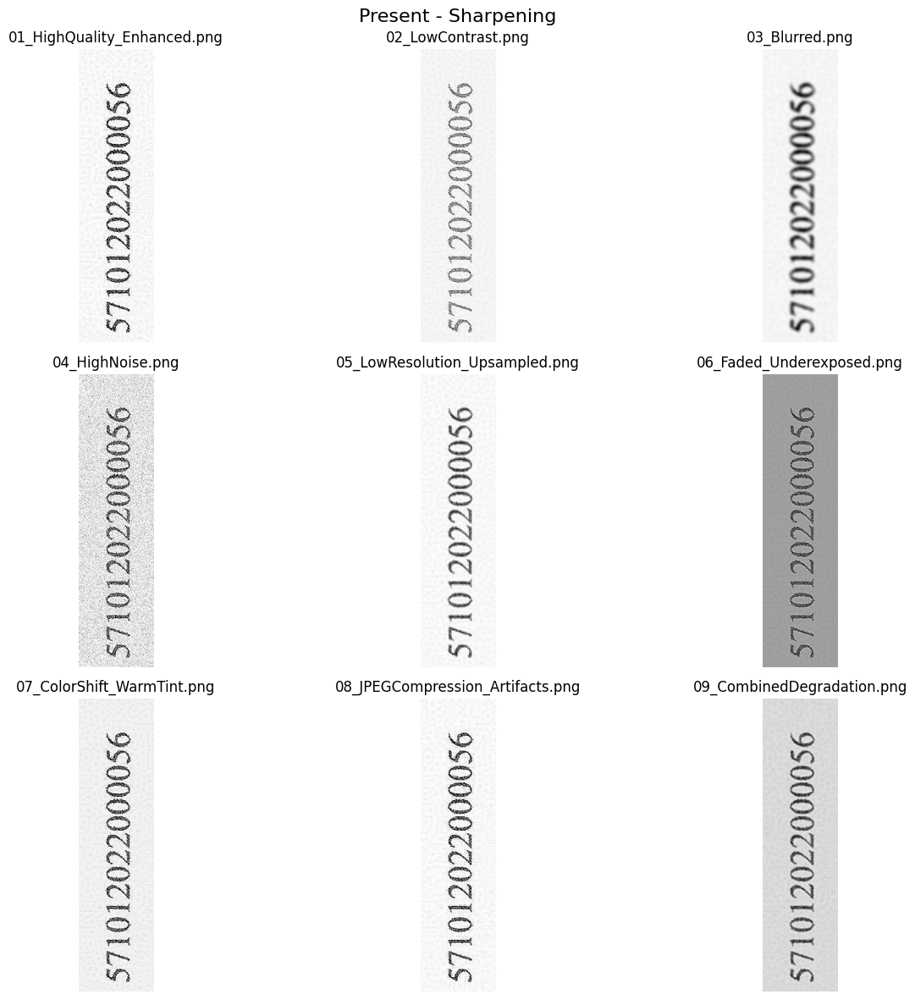

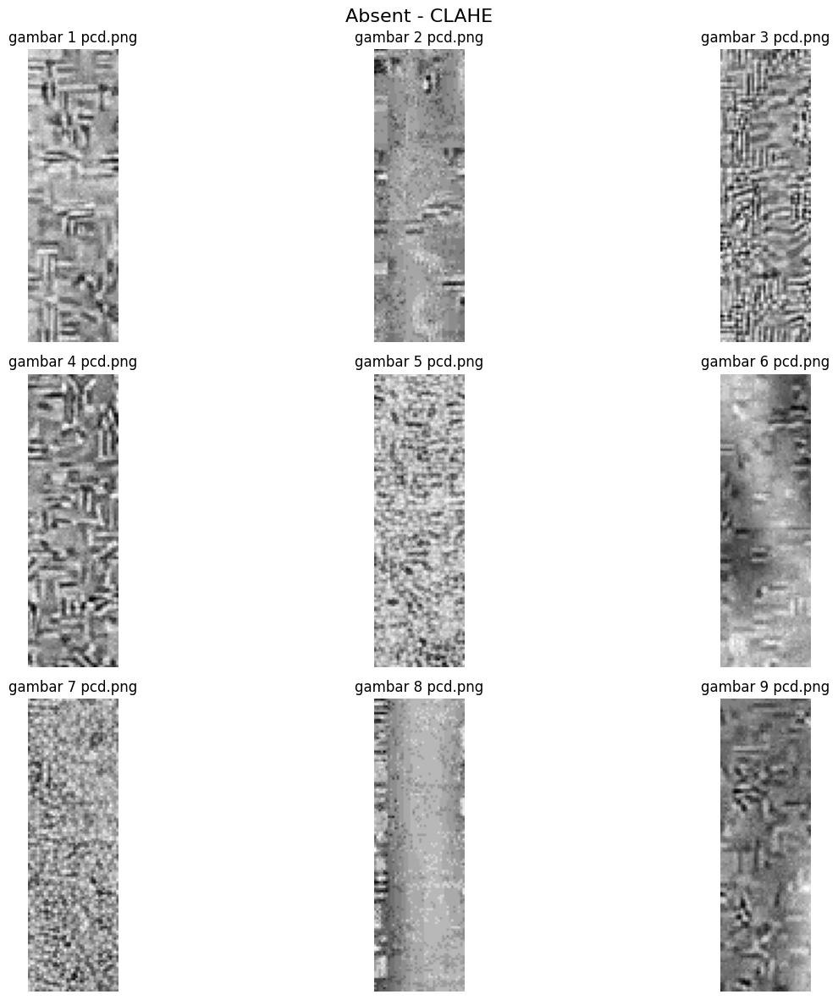

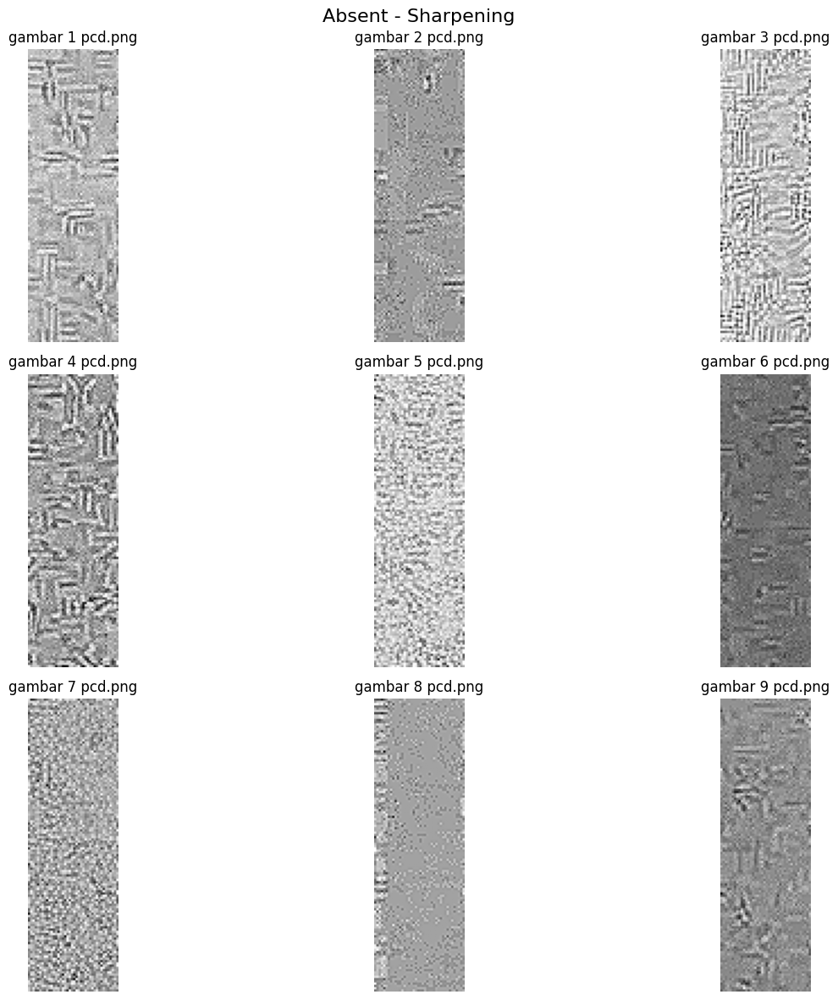

In [32]:
import os
import cv2
import matplotlib.pyplot as plt

for kategori in ["Present", "Absent"]:
    folder_asli = f"/content/drive/MyDrive/PCD7_Enhancement/{kategori}"

    for metode in ["CLAHE", "Sharpening"]:
        folder = os.path.join(folder_asli, metode)

        if not os.path.exists(folder):
            print(f"Folder belum ditemukan: {folder}")
            continue

        daftar_file = sorted(os.listdir(folder))
        jumlah = len(daftar_file)

        if jumlah == 0:
            print(f"Tidak ada gambar di: {folder}")
            continue

        fig, axes = plt.subplots(
            (jumlah + 2) // 3, 3,
            figsize=(15, 4 * ((jumlah + 2) // 3))
        )
        axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

        for i, nama_file in enumerate(daftar_file):
            path = os.path.join(folder, nama_file)
            gambar = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

            if gambar is not None:
                axes[i].imshow(gambar, cmap="gray")
                axes[i].set_title(nama_file)
            axes[i].axis("off")

        for i in range(jumlah, len(axes)):
            axes[i].axis("off")

        plt.suptitle(f"{kategori} - {metode}", fontsize=16)
        plt.tight_layout()
        plt.show()

#OCR

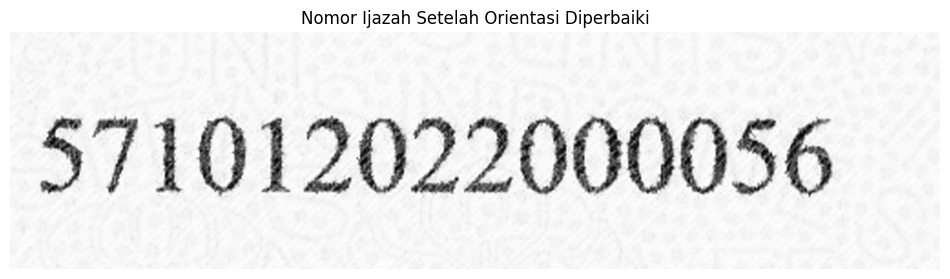

Nama gambar: 01_HighQuality_Enhanced.jpg
Hasil OCR: 571012022000056


In [37]:
# Ambil potongan nomor ijazah
nama_file = next(iter(hasil_present))
nomor_gray = hasil_present[nama_file]["nomor"]

# Putar 90 derajat searah jarum jam
nomor_putar = cv2.rotate(
    nomor_gray,
    cv2.ROTATE_90_CLOCKWISE
)

# Perbesar gambar
nomor_besar = cv2.resize(
    nomor_putar,
    None,
    fx=3,
    fy=3,
    interpolation=cv2.INTER_CUBIC
)

# Jalankan OCR khusus angka
teks_ocr = pytesseract.image_to_string(
    nomor_besar,
    config="--psm 7 -c tessedit_char_whitelist=0123456789"
).strip()

# Tampilkan hasil
plt.figure(figsize=(12, 4))
plt.imshow(nomor_besar, cmap="gray")
plt.title("Nomor Ijazah Setelah Orientasi Diperbaiki")
plt.axis("off")
plt.show()

print("Nama gambar:", nama_file)
print("Hasil OCR:", teks_ocr if teks_ocr else "(belum terbaca)")

##Terapkan OCR ke semua gambar

In [38]:
hasil_semua_ocr = []

# Proses kedua kategori
for kategori, data_gambar in [
    ("Present", hasil_present),
    ("Absent", hasil_absent)
]:
    print(f"\n{'=' * 20} {kategori} {'=' * 20}")

    for nama_file, data in data_gambar.items():
        nomor_gray = data["nomor"]

        # Putar agar nomor mendatar dan terbaca normal
        nomor_putar = cv2.rotate(
            nomor_gray,
            cv2.ROTATE_90_CLOCKWISE
        )

        # Perbesar gambar sebelum OCR
        nomor_besar = cv2.resize(
            nomor_putar,
            None,
            fx=3,
            fy=3,
            interpolation=cv2.INTER_CUBIC
        )

        # OCR khusus angka
        teks_ocr = pytesseract.image_to_string(
            nomor_besar,
            config=(
                "--psm 7 "
                "-c tessedit_char_whitelist=0123456789"
            )
        ).strip()

        hasil_semua_ocr.append({
            "Kategori": kategori,
            "Nama Gambar": nama_file,
            "Nomor OCR": teks_ocr
        })

        print(f"{nama_file} -> {teks_ocr or '(tidak terbaca)'}")

# Buat tabel hasil
df_ocr = pd.DataFrame(hasil_semua_ocr)

print("\nTabel hasil OCR:")
display(df_ocr)

# Simpan hasil OCR ke CSV
folder_output = "/content/drive/MyDrive/PCD7_Enhancement"
os.makedirs(folder_output, exist_ok=True)

path_csv = os.path.join(
    folder_output,
    "hasil_ocr_nomor.csv"
)

df_ocr.to_csv(path_csv, index=False)

print("\nHasil OCR disimpan di:", path_csv)


==================== Present ====================
01_HighQuality_Enhanced.jpg -> 571012022000056
02_LowContrast.jpg -> 571012022000056
03_Blurred.jpg -> 571012022000056
04_HighNoise.jpg -> 5371012022000056
05_LowResolution_Upsampled.jpg -> 571012022000056
06_Faded_Underexposed.jpg -> 571012022000056
07_ColorShift_WarmTint.jpg -> 571012022000056
08_JPEGCompression_Artifacts.jpg -> 571012022000056
09_CombinedDegradation.jpg -> 571012022000056

==================== Absent ====================
gambar 1 pcd.jpg -> (tidak terbaca)
gambar 2 pcd.jpg -> (tidak terbaca)
gambar 3 pcd.jpg -> (tidak terbaca)
gambar 4 pcd.jpg -> (tidak terbaca)
gambar 5 pcd.jpg -> (tidak terbaca)
gambar 6 pcd.jpg -> (tidak terbaca)
gambar 7 pcd.jpg -> (tidak terbaca)
gambar 8 pcd.jpg -> (tidak terbaca)
gambar 9 pcd.jpg -> (tidak terbaca)

Tabel hasil OCR:


,Kategori,Nama Gambar,Nomor OCR
0,Present,01_HighQuality_Enhanced.jpg,571012022000056
1,Present,02_LowContrast.jpg,571012022000056
2,Present,03_Blurred.jpg,571012022000056
3,Present,04_HighNoise.jpg,5371012022000056
4,Present,05_LowResolution_Upsampled.jpg,571012022000056
5,Present,06_Faded_Underexposed.jpg,571012022000056
6,Present,07_ColorShift_WarmTint.jpg,571012022000056
7,Present,08_JPEGCompression_Artifacts.jpg,571012022000056
8,Present,09_CombinedDegradation.jpg,571012022000056
9,Absent,gambar 1 pcd.jpg,



Hasil OCR disimpan di: /content/drive/MyDrive/PCD7_Enhancement/hasil_ocr_nomor.csv


##Evaluasi OCR menggunakan CER (Character Error Rate)

In [41]:

import pandas as pd

path_csv = "/content/drive/MyDrive/PCD7_Enhancement/hasil_ocr_nomor.csv"

df_ocr = pd.read_csv(path_csv)

display(df_ocr)

,Kategori,Nama Gambar,Nomor OCR
0,Present,01_HighQuality_Enhanced.jpg,5.710120e+14
1,Present,02_LowContrast.jpg,5.710120e+14
2,Present,03_Blurred.jpg,5.710120e+14
3,Present,04_HighNoise.jpg,5.371012e+15
4,Present,05_LowResolution_Upsampled.jpg,5.710120e+14
5,Present,06_Faded_Underexposed.jpg,5.710120e+14
6,Present,07_ColorShift_WarmTint.jpg,5.710120e+14
7,Present,08_JPEGCompression_Artifacts.jpg,5.710120e+14
8,Present,09_CombinedDegradation.jpg,5.710120e+14
9,Absent,gambar 1 pcd.jpg,NaN


In [40]:
path_csv = "/content/drive/MyDrive/PCD7_Enhancement/hasil_ocr_nomor.csv"

# Baca ulang hasil OCR sebagai teks
df_ocr = pd.read_csv(path_csv, dtype=str)

# Bersihkan spasi dan nilai kosong
df_ocr["Nomor OCR"] = df_ocr["Nomor OCR"].fillna("").str.strip()

# Tampilkan hasil tanpa notasi ilmiah
pd.set_option("display.max_colwidth", None)
display(df_ocr)

,Kategori,Nama Gambar,Nomor OCR
0,Present,01_HighQuality_Enhanced.jpg,571012022000056
1,Present,02_LowContrast.jpg,571012022000056
2,Present,03_Blurred.jpg,571012022000056
3,Present,04_HighNoise.jpg,5371012022000056
4,Present,05_LowResolution_Upsampled.jpg,571012022000056
5,Present,06_Faded_Underexposed.jpg,571012022000056
6,Present,07_ColorShift_WarmTint.jpg,571012022000056
7,Present,08_JPEGCompression_Artifacts.jpg,571012022000056
8,Present,09_CombinedDegradation.jpg,571012022000056
9,Absent,gambar 1 pcd.jpg,


In [52]:
hasil_ocr_perbandingan = []

for kategori, data_gambar in [
    ("Present", hasil_present),
    ("Absent", hasil_absent)
]:
    for nama_file, data in data_gambar.items():
        nomor_gray = data["nomor"]

        # Nomor pada crop sebelumnya dibaca setelah rotasi 90 derajat
        nomor_rotasi = cv2.rotate(
            nomor_gray, cv2.ROTATE_90_CLOCKWISE
        )

        nomor_besar = cv2.resize(
            nomor_rotasi,
            None,
            fx=4,
            fy=4,
            interpolation=cv2.INTER_CUBIC
        )

        # Opsi A: grayscale diperbesar
        teks_a = pytesseract.image_to_string(
            nomor_besar,
            config="--psm 7 -c tessedit_char_whitelist=0123456789"
        )

        # Opsi B: threshold Otsu
        _, nomor_otsu = cv2.threshold(
            nomor_besar, 0, 255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        teks_b = pytesseract.image_to_string(
            nomor_otsu,
            config="--psm 7 -c tessedit_char_whitelist=0123456789"
        )

        # Opsi C: CLAHE lalu threshold
        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(4, 4)
        )
        nomor_clahe = clahe.apply(nomor_besar)
        _, nomor_clahe_bin = cv2.threshold(
            nomor_clahe, 0, 255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        teks_c = pytesseract.image_to_string(
            nomor_clahe_bin,
            config="--psm 7 -c tessedit_char_whitelist=0123456789"
        )

        bersihkan = lambda teks: "".join(
            c for c in teks if c.isdigit()
        )

        hasil_ocr_perbandingan.append({
            "Kategori": kategori,
            "Nama File": nama_file,
            "OCR Grayscale": bersihkan(teks_a),
            "OCR Otsu": bersihkan(teks_b),
            "OCR CLAHE+Otsu": bersihkan(teks_c)
        })

df_ocr_perbandingan = pd.DataFrame(hasil_ocr_perbandingan)
display(df_ocr_perbandingan)

folder_hasil = "/content/drive/MyDrive/PCD7_Enhancement"
os.makedirs(folder_hasil, exist_ok=True)

df_ocr_perbandingan.to_csv(
    os.path.join(folder_hasil, "perbandingan_ocr.csv"),
    index=False
)

print("Perbandingan OCR tersimpan.")

,Kategori,Nama File,OCR Grayscale,OCR Otsu,OCR CLAHE+Otsu
0,Present,01_HighQuality_Enhanced.jpg,5371012022000056,5371012022000056,5371012022000056
1,Present,02_LowContrast.jpg,371012022000056,5371012022000056,5371012022000056
2,Present,03_Blurred.jpg,571012022000056,571012022000056,571012022000056
3,Present,04_HighNoise.jpg,5371012022000056,571012022000056,
4,Present,05_LowResolution_Upsampled.jpg,571012022000056,571012022000056,371012022000056
5,Present,06_Faded_Underexposed.jpg,371012022000056,5371012022000056,571012022000056
6,Present,07_ColorShift_WarmTint.jpg,5371012022000056,5371012022000056,5371012022000056
7,Present,08_JPEGCompression_Artifacts.jpg,571012022000056,571012022000056,5371012022000056
8,Present,09_CombinedDegradation.jpg,5371012022000056,571012022000056,571012022000056
9,Absent,gambar 1 pcd.jpg,,,


Perbandingan OCR tersimpan.


##Hitung CER untuk membandingkan metode enhancement



In [53]:

def hitung_cer(referensi, prediksi):
    # Levenshtein distance: jumlah substitusi, penghapusan,
    # dan penyisipan karakter minimum
    referensi = str(referensi).strip()
    prediksi = str(prediksi).strip()

    if not referensi:
        return np.nan

    n, m = len(referensi), len(prediksi)
    dp = [[0] * (m + 1) for _ in range(n + 1)]

    for i in range(n + 1):
        dp[i][0] = i
    for j in range(m + 1):
        dp[0][j] = j

    for i in range(1, n + 1):
        for j in range(1, m + 1):
            biaya = 0 if referensi[i - 1] == prediksi[j - 1] else 1
            dp[i][j] = min(
                dp[i - 1][j] + 1,
                dp[i][j - 1] + 1,
                dp[i - 1][j - 1] + biaya
            )

    return dp[n][m] / n

# Isi berdasarkan nomor yang benar-benar tercetak pada masing-masing ijazah.
# Biarkan kosong dulu jika belum diverifikasi.
nomor_referensi = {
    # Contoh format:
    # "01_HighQuality_Enhanced.jpg": "NOMOR_SEBENARNYA",
    # "gambar 1 pcd.jpg": "NOMOR_SEBENARNYA",
}

baris_cer = []

for _, baris in df_ocr_perbandingan.iterrows():
    nama = baris["Nama File"]
    referensi = nomor_referensi.get(nama, "")

    for kolom in ["OCR Grayscale", "OCR Otsu", "OCR CLAHE+Otsu"]:
        if referensi:
            cer = hitung_cer(referensi, baris[kolom])
        else:
            cer = np.nan

        baris_cer.append({
            "Nama File": nama,
            "Metode": kolom,
            "Nomor Referensi": referensi,
            "Hasil OCR": baris[kolom],
            "CER (%)": round(cer * 100, 2) if not np.isnan(cer) else np.nan
        })

df_cer = pd.DataFrame(baris_cer)
display(df_cer)

df_cer.to_csv(
    "/content/drive/MyDrive/PCD7_Enhancement/hasil_cer.csv",
    index=False
)

print(
    "CER dihitung untuk data yang sudah memiliki nomor referensi. "
    "Nilai kosong berarti nomor referensinya belum diisi."
)

,Nama File,Metode,Nomor Referensi,Hasil OCR,CER (%)
0,01_HighQuality_Enhanced.jpg,OCR Grayscale,,5371012022000056,NaN
1,01_HighQuality_Enhanced.jpg,OCR Otsu,,5371012022000056,NaN
2,01_HighQuality_Enhanced.jpg,OCR CLAHE+Otsu,,5371012022000056,NaN
3,02_LowContrast.jpg,OCR Grayscale,,371012022000056,NaN
4,02_LowContrast.jpg,OCR Otsu,,5371012022000056,NaN
5,02_LowContrast.jpg,OCR CLAHE+Otsu,,5371012022000056,NaN
6,03_Blurred.jpg,OCR Grayscale,,571012022000056,NaN
7,03_Blurred.jpg,OCR Otsu,,571012022000056,NaN
8,03_Blurred.jpg,OCR CLAHE+Otsu,,571012022000056,NaN
9,04_HighNoise.jpg,OCR Grayscale,,5371012022000056,NaN


CER dihitung untuk data yang sudah memiliki nomor referensi. Nilai kosong berarti nomor referensinya belum diisi.


#thresholding untuk bagian ttd dekan

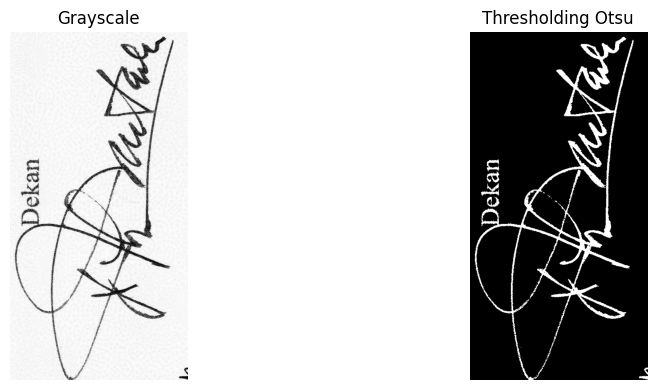

In [44]:
# Ambil satu contoh gambar dari kategori Present
nama_file = list(hasil_present.keys())[0]
ttd_gray = hasil_present[nama_file]["ttd"]

# Thresholding Otsu
_, ttd_threshold = cv2.threshold(
    ttd_gray,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Tampilkan hasil
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(ttd_gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(ttd_threshold, cmap="gray")
plt.title("Thresholding Otsu")
plt.axis("off")

plt.tight_layout()
plt.show()

Present: 9 gambar berhasil diproses.
Absent: 9 gambar berhasil diproses.
Semua hasil thresholding tersimpan.


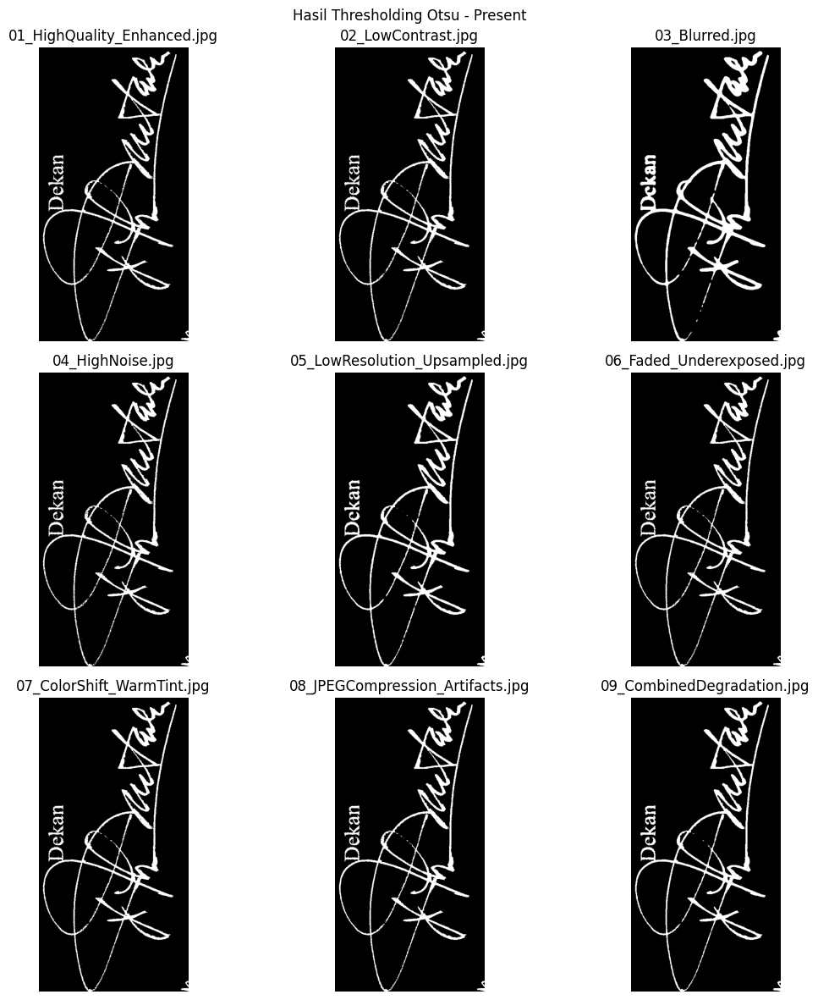

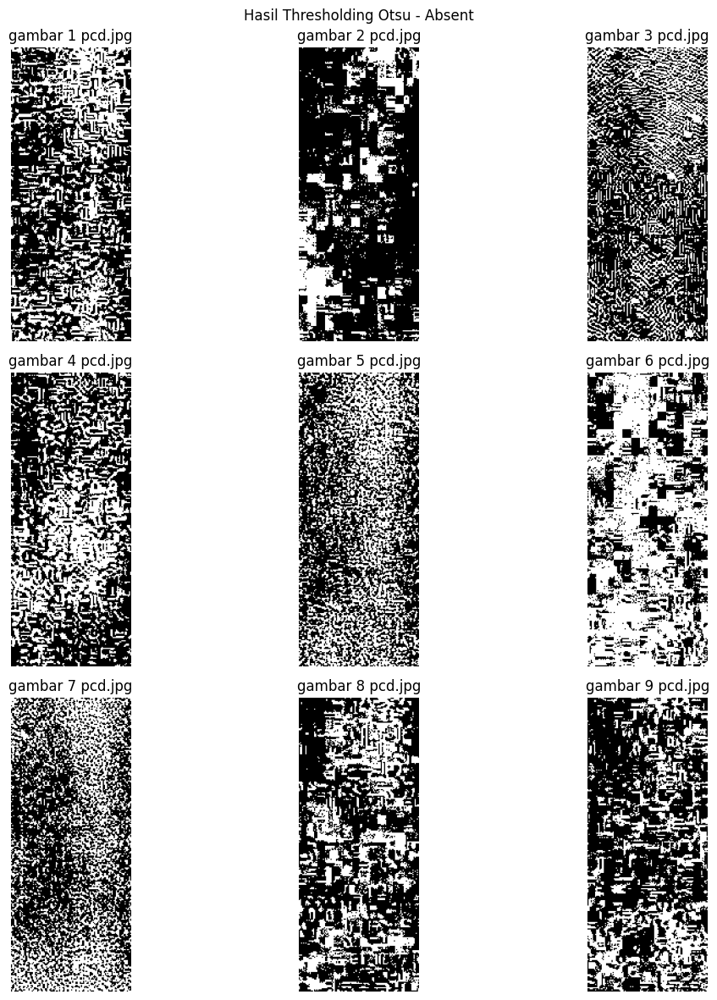

In [45]:
# Menyimpan hasil thresholding
hasil_threshold_present = {}
hasil_threshold_absent = {}

folder_threshold = "/content/drive/MyDrive/PCD7_Enhancement/Thresholding"

for kategori, data_gambar, hasil_dict in [
    ("Present", hasil_present, hasil_threshold_present),
    ("Absent", hasil_absent, hasil_threshold_absent)
]:
    folder_simpan = os.path.join(folder_threshold, kategori)
    os.makedirs(folder_simpan, exist_ok=True)

    for nama_file, data in data_gambar.items():
        # Mengambil crop tanda tangan grayscale
        ttd_gray = data["ttd"]

        # Thresholding Otsu
        _, ttd_threshold = cv2.threshold(
            ttd_gray,
            0,
            255,
            cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
        )

        # Menyimpan hasil ke dictionary
        hasil_dict[nama_file] = ttd_threshold

        # Menyimpan gambar ke Google Drive
        nama_simpan = os.path.splitext(nama_file)[0] + "_threshold.png"
        path_simpan = os.path.join(folder_simpan, nama_simpan)
        cv2.imwrite(path_simpan, ttd_threshold)

    print(f"{kategori}: {len(hasil_dict)} gambar berhasil diproses.")

print("Semua hasil thresholding tersimpan.")

# Menampilkan seluruh hasil thresholding
for kategori, hasil_dict in [
    ("Present", hasil_threshold_present),
    ("Absent", hasil_threshold_absent)
]:
    jumlah = len(hasil_dict)
    baris = (jumlah + 2) // 3

    fig, axes = plt.subplots(
        baris, 3,
        figsize=(12, 4 * baris)
    )
    axes = axes.flatten()

    for i, (nama_file, gambar) in enumerate(hasil_dict.items()):
        axes[i].imshow(gambar, cmap="gray")
        axes[i].set_title(nama_file)
        axes[i].axis("off")

    for i in range(jumlah, len(axes)):
        axes[i].axis("off")

    plt.suptitle(f"Hasil Thresholding Otsu - {kategori}")
    plt.tight_layout()
    plt.show()

##Operasi morfologi ke semua gambar Present dan Absent

Present: 9 gambar selesai diproses.
Absent: 9 gambar selesai diproses.
Semua hasil morfologi berhasil disimpan.


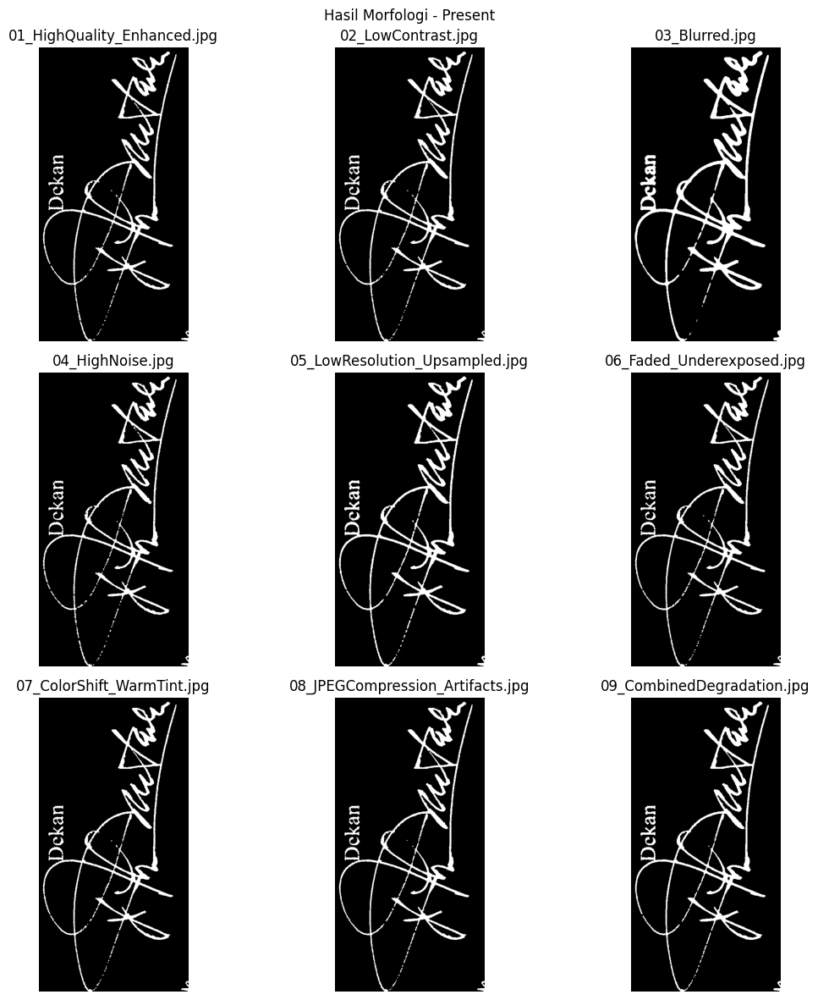

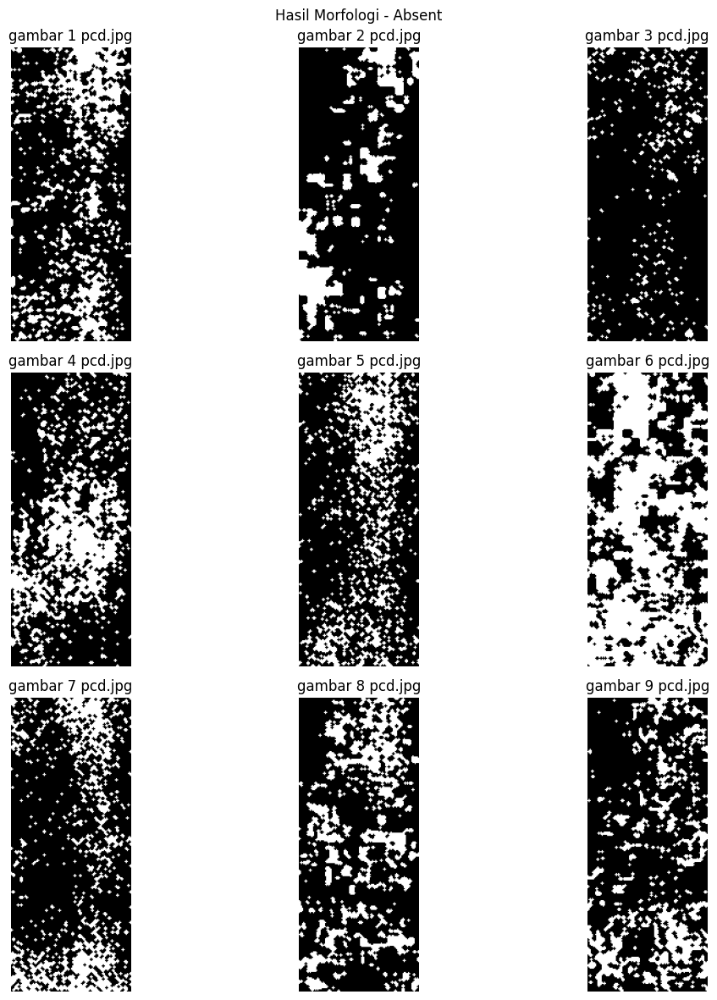

In [47]:
# Dictionary untuk menyimpan hasil morfologi
hasil_morfologi_present = {}
hasil_morfologi_absent = {}

# Kernel untuk operasi morfologi
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (3, 3)
)

folder_morfologi = (
    "/content/drive/MyDrive/PCD7_Enhancement/Morfologi"
)

for kategori, data_threshold, hasil_dict in [
    ("Present", hasil_threshold_present, hasil_morfologi_present),
    ("Absent", hasil_threshold_absent, hasil_morfologi_absent)
]:
    folder_simpan = os.path.join(folder_morfologi, kategori)
    os.makedirs(folder_simpan, exist_ok=True)

    for nama_file, gambar_threshold in data_threshold.items():

        # Opening: mengurangi noise kecil
        gambar_opening = cv2.morphologyEx(
            gambar_threshold,
            cv2.MORPH_OPEN,
            kernel
        )

        # Closing: membantu menyambungkan goresan
        gambar_closing = cv2.morphologyEx(
            gambar_opening,
            cv2.MORPH_CLOSE,
            kernel
        )

        # Simpan hasil akhir morfologi
        hasil_dict[nama_file] = gambar_closing

        nama_simpan = (
            os.path.splitext(nama_file)[0] + "_morfologi.png"
        )
        cv2.imwrite(
            os.path.join(folder_simpan, nama_simpan),
            gambar_closing
        )

    print(
        f"{kategori}: {len(hasil_dict)} gambar selesai diproses."
    )

print("Semua hasil morfologi berhasil disimpan.")

# Tampilkan semua hasil Present dan Absent
for kategori, hasil_dict in [
    ("Present", hasil_morfologi_present),
    ("Absent", hasil_morfologi_absent)
]:
    jumlah = len(hasil_dict)
    baris = (jumlah + 2) // 3

    fig, axes = plt.subplots(
        baris, 3,
        figsize=(12, 4 * baris)
    )
    axes = axes.flatten()

    for i, (nama_file, gambar) in enumerate(hasil_dict.items()):
        axes[i].imshow(gambar, cmap="gray")
        axes[i].set_title(nama_file)
        axes[i].axis("off")

    for i in range(jumlah, len(axes)):
        axes[i].axis("off")

    plt.suptitle(f"Hasil Morfologi - {kategori}")
    plt.tight_layout()
    plt.show()

##Deteksi TTd

In [48]:
hasil_deteksi_ttd = []

# Gabungkan data Present dan Absent
for kategori, data_gambar in [
    ("Present", hasil_morfologi_present),
    ("Absent", hasil_morfologi_absent)
]:
    for nama_file, gambar in data_gambar.items():

        # Hitung jumlah piksel putih
        jumlah_putih = cv2.countNonZero(gambar)

        # Hitung total piksel
        total_piksel = gambar.shape[0] * gambar.shape[1]

        # Persentase piksel putih
        persentase_putih = (jumlah_putih / total_piksel) * 100

        hasil_deteksi_ttd.append({
            "Nama File": nama_file,
            "Kategori Aktual": kategori,
            "Piksel Putih (%)": round(persentase_putih, 2)
        })

# Buat tabel hasil
df_deteksi_ttd = pd.DataFrame(hasil_deteksi_ttd)

display(df_deteksi_ttd)

,Nama File,Kategori Aktual,Piksel Putih (%)
0,01_HighQuality_Enhanced.jpg,Present,8.27
1,02_LowContrast.jpg,Present,8.38
2,03_Blurred.jpg,Present,11.94
3,04_HighNoise.jpg,Present,8.02
4,05_LowResolution_Upsampled.jpg,Present,9.29
5,06_Faded_Underexposed.jpg,Present,8.39
6,07_ColorShift_WarmTint.jpg,Present,8.37
7,08_JPEGCompression_Artifacts.jpg,Present,8.46
8,09_CombinedDegradation.jpg,Present,9.01
9,gambar 1 pcd.jpg,Absent,28.31


In [49]:

# Ambang awal untuk klasifikasi
ambang = 15.0

df_deteksi_ttd["Prediksi"] = df_deteksi_ttd[
    "Piksel Putih (%)"
].apply(
    lambda x: "Present" if x < ambang else "Absent"
)

# Bandingkan prediksi dengan kategori aktual
df_deteksi_ttd["Hasil"] = df_deteksi_ttd.apply(
    lambda baris: (
        "Benar"
        if baris["Kategori Aktual"] == baris["Prediksi"]
        else "Salah"
    ),
    axis=1
)

# Hitung akurasi
jumlah_benar = (df_deteksi_ttd["Hasil"] == "Benar").sum()
jumlah_data = len(df_deteksi_ttd)
akurasi = jumlah_benar / jumlah_data * 100

print(f"Jumlah data       : {jumlah_data}")
print(f"Prediksi benar    : {jumlah_benar}")
print(f"Prediksi salah    : {jumlah_data - jumlah_benar}")
print(f"Akurasi awal      : {akurasi:.2f}%")

display(df_deteksi_ttd)

Jumlah data       : 18
Prediksi benar    : 17
Prediksi salah    : 1
Akurasi awal      : 94.44%


,Nama File,Kategori Aktual,Piksel Putih (%),Prediksi,Hasil
0,01_HighQuality_Enhanced.jpg,Present,8.27,Present,Benar
1,02_LowContrast.jpg,Present,8.38,Present,Benar
2,03_Blurred.jpg,Present,11.94,Present,Benar
3,04_HighNoise.jpg,Present,8.02,Present,Benar
4,05_LowResolution_Upsampled.jpg,Present,9.29,Present,Benar
5,06_Faded_Underexposed.jpg,Present,8.39,Present,Benar
6,07_ColorShift_WarmTint.jpg,Present,8.37,Present,Benar
7,08_JPEGCompression_Artifacts.jpg,Present,8.46,Present,Benar
8,09_CombinedDegradation.jpg,Present,9.01,Present,Benar
9,gambar 1 pcd.jpg,Absent,28.31,Absent,Benar


#PERBAIKAN

In [51]:
def ekstrak_fitur_ttd(gambar):
    # Piksel putih mewakili goresan setelah thresholding terbalik
    total = gambar.size
    jumlah_putih = cv2.countNonZero(gambar)
    kepadatan = jumlah_putih / total if total else 0

    # Cari komponen yang saling terhubung
    jumlah_label, label, statistik, _ = cv2.connectedComponentsWithStats(
        gambar, connectivity=8
    )

    luas = statistik[1:, cv2.CC_STAT_AREA] if jumlah_label > 1 else []
    luas_valid = [int(a) for a in luas if a >= 3]

    komponen = len(luas_valid)
    luas_terbesar = max(luas_valid, default=0) / total if total else 0

    return [
        kepadatan,
        komponen,
        luas_terbesar,
        gambar.shape[1] / gambar.shape[0]
    ]

X, y, nama_data = [], [], []

for kategori, data_gambar in [
    ("Present", hasil_morfologi_present),
    ("Absent", hasil_morfologi_absent)
]:
    for nama_file, gambar in data_gambar.items():
        X.append(ekstrak_fitur_ttd(gambar))
        y.append(kategori)
        nama_data.append(nama_file)

X = np.array(X, dtype=float)
y = np.array(y)

# Evaluasi silang: setiap gambar diprediksi saat tidak menjadi data latih
model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SVC(kernel="rbf", class_weight="balanced")
)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
prediksi_cv = cross_val_predict(model, X, y, cv=cv)

df_evaluasi_ttd = pd.DataFrame({
    "Nama File": nama_data,
    "Kategori Aktual": y,
    "Prediksi": prediksi_cv,
    "Hasil": np.where(y == prediksi_cv, "Benar", "Salah")
})

akurasi_cv = accuracy_score(y, prediksi_cv) * 100
print(f"Akurasi evaluasi silang 3-fold: {akurasi_cv:.2f}%")
print("\nLaporan klasifikasi:")
print(classification_report(y, prediksi_cv, zero_division=0))
print("Confusion matrix (urutan kelas Absent, Present):")
print(confusion_matrix(y, prediksi_cv, labels=["Absent", "Present"]))

display(df_evaluasi_ttd)

df_evaluasi_ttd.to_csv(
    "/content/drive/MyDrive/PCD7_Enhancement/evaluasi_ttd.csv",
    index=False
)

Akurasi evaluasi silang 3-fold: 100.00%

Laporan klasifikasi:
              precision    recall  f1-score   support

      Absent       1.00      1.00      1.00         9
     Present       1.00      1.00      1.00         9

    accuracy                           1.00        18
   macro avg       1.00      1.00      1.00        18
weighted avg       1.00      1.00      1.00        18

Confusion matrix (urutan kelas Absent, Present):
[[9 0]
 [0 9]]


,Nama File,Kategori Aktual,Prediksi,Hasil
0,01_HighQuality_Enhanced.jpg,Present,Present,Benar
1,02_LowContrast.jpg,Present,Present,Benar
2,03_Blurred.jpg,Present,Present,Benar
3,04_HighNoise.jpg,Present,Present,Benar
4,05_LowResolution_Upsampled.jpg,Present,Present,Benar
5,06_Faded_Underexposed.jpg,Present,Present,Benar
6,07_ColorShift_WarmTint.jpg,Present,Present,Benar
7,08_JPEGCompression_Artifacts.jpg,Present,Present,Benar
8,09_CombinedDegradation.jpg,Present,Present,Benar
9,gambar 1 pcd.jpg,Absent,Absent,Benar


In [55]:

# Gabungkan prediksi tanda tangan dengan hasil OCR
df_final = df_evaluasi_ttd[
    ["Nama File", "Kategori Aktual", "Prediksi"]
].merge(
    df_ocr_perbandingan[
        ["Nama File", "OCR Grayscale", "OCR Otsu", "OCR CLAHE+Otsu"]
    ],
    on="Nama File",
    how="left"
)

df_final = df_final.rename(columns={
    "Kategori Aktual": "Label Tanda Tangan Aktual",
    "Prediksi": "Status Tanda Tangan Terdeteksi"
})

display(df_final)

df_final.to_csv(
    "/content/drive/MyDrive/PCD7_Enhancement/hasil_verifikasi_akhir.csv",
    index=False
)

print("Tabel verifikasi akhir berhasil disimpan.")

,Nama File,Label Tanda Tangan Aktual,Status Tanda Tangan Terdeteksi,OCR Grayscale,OCR Otsu,OCR CLAHE+Otsu
0,01_HighQuality_Enhanced.jpg,Present,Present,5371012022000056,5371012022000056,5371012022000056
1,02_LowContrast.jpg,Present,Present,371012022000056,5371012022000056,5371012022000056
2,03_Blurred.jpg,Present,Present,571012022000056,571012022000056,571012022000056
3,04_HighNoise.jpg,Present,Present,5371012022000056,571012022000056,
4,05_LowResolution_Upsampled.jpg,Present,Present,571012022000056,571012022000056,371012022000056
5,06_Faded_Underexposed.jpg,Present,Present,371012022000056,5371012022000056,571012022000056
6,07_ColorShift_WarmTint.jpg,Present,Present,5371012022000056,5371012022000056,5371012022000056
7,08_JPEGCompression_Artifacts.jpg,Present,Present,571012022000056,571012022000056,5371012022000056
8,09_CombinedDegradation.jpg,Present,Present,5371012022000056,571012022000056,571012022000056
9,gambar 1 pcd.jpg,Absent,Absent,,,


Tabel verifikasi akhir berhasil disimpan.
